In [1]:
#Male cardio analiza
#1.Ucitvanje i formiranje dataseta

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import kagglehub

from kagglehub import KaggleDatasetAdapter

df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "valakhorasani/gym-members-exercise-dataset",
    "gym_members_exercise_tracking.csv"
)

print("Dimenzije celog dataseta:", df.shape)

/Users/brankomitic/DataspellProjects/alternativni_dataset_diplomski/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/var/folders/28/tt6vttm91r1c29lt4s1fr9z40000gn/T/ipykernel_1367/904456173.py:9: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Dimenzije celog dataseta: (973, 15)


In [3]:
df_mc = df[
    (df['Gender'] == 'Male') &
    (df['Workout_Type'] == 'Cardio')
].copy()

print("Dimenzije Male Cardio dataseta:", df_mc.shape)

Dimenzije Male Cardio dataseta: (129, 15)


In [4]:
## 2. Priprema podataka

### 2.1. Provera NA vrednosti

In [5]:
print(df_mc.isnull().sum())

Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Workout_Type                     0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
dtype: int64


In [6]:
#Analogno proslim nema nan vrednosti

In [7]:
### 2.2. Korelaciona analiza

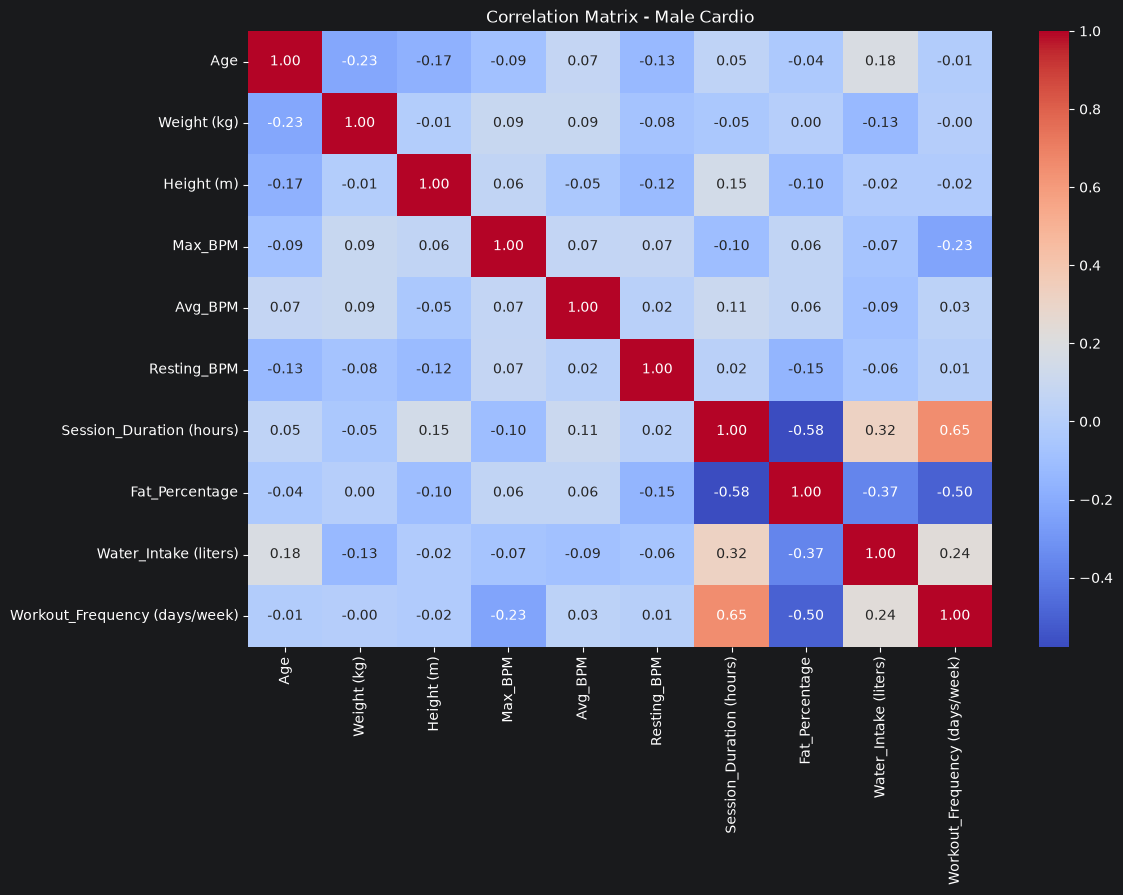

In [8]:
features = [
    'Age',
    'Weight (kg)',
    'Height (m)',
    'Max_BPM',
    'Avg_BPM',
    'Resting_BPM',
    'Session_Duration (hours)',
    'Fat_Percentage',
    'Water_Intake (liters)',
    'Workout_Frequency (days/week)'
]

corr_matrix = df_mc[features].corr()

plt.figure(figsize=(12, 8))
sb.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix - Male Cardio')
plt.show()

In [9]:
#Vec znamo koje features treba da stavimo iz proslih df da nemamo nista preko 0.7

In [10]:
### 2.3. Analiza outliera

In [11]:
Q1 = df_mc[features].quantile(0.25)
Q3 = df_mc[features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_df = pd.DataFrame({
    'Donji outlieri': (df_mc[features] < lower_bound).sum(),
    'Gornji outlieri': (df_mc[features] > upper_bound).sum()
})

outliers_df['Ukupno'] = outliers_df.sum(axis=1)

print(outliers_df)

                               Donji outlieri  Gornji outlieri  Ukupno
Age                                         0                0       0
Weight (kg)                                 0                0       0
Height (m)                                  0                0       0
Max_BPM                                     0                0       0
Avg_BPM                                     0                0       0
Resting_BPM                                 0                0       0
Session_Duration (hours)                    0                0       0
Fat_Percentage                             10                0      10
Water_Intake (liters)                       0                0       0
Workout_Frequency (days/week)               0                0       0


In [12]:
#Opet fat percentage ima outliere

In [13]:
column = 'Fat_Percentage'

print("Vrednosti donjih outliera:")
print(df_mc.loc[df_mc[column] < lower_bound[column], column].values)

for limit in np.arange(0.01, 0.11, 0.01):
    lower = df_mc[column].quantile(limit)

    n_outliers = (
        (df_mc[column] < lower_bound[column]) &
        (df_mc[column] < lower)
    ).sum()

    print(f"Limit {limit:.2f}: {n_outliers} donjih outliera")

Vrednosti donjih outliera:
[11.  10.7 11.6 11.  11.1 11.6 11.1 10.1 10.5 11.8]
Limit 0.01: 2 donjih outliera
Limit 0.02: 3 donjih outliera
Limit 0.03: 3 donjih outliera
Limit 0.04: 5 donjih outliera
Limit 0.05: 7 donjih outliera
Limit 0.06: 7 donjih outliera
Limit 0.07: 9 donjih outliera
Limit 0.08: 10 donjih outliera
Limit 0.09: 10 donjih outliera
Limit 0.10: 10 donjih outliera


In [14]:
from scipy.stats.mstats import winsorize

column = 'Fat_Percentage'

for limit in np.arange(0.01, 0.11, 0.01):
    temp = pd.Series(
        np.asarray(
            winsorize(
                df_mc[column].to_numpy().copy(),
                limits=[limit, 0]
            )
        )
    )

    Q1_temp = temp.quantile(0.25)
    Q3_temp = temp.quantile(0.75)
    IQR_temp = Q3_temp - Q1_temp

    lower_temp = Q1_temp - 1.5 * IQR_temp

    n_outliers = (temp < lower_temp).sum()

    print(f"Limit {limit:.2f}: {n_outliers} outliera")

Limit 0.01: 10 outliera
Limit 0.02: 10 outliera
Limit 0.03: 10 outliera
Limit 0.04: 10 outliera
Limit 0.05: 10 outliera
Limit 0.06: 10 outliera
Limit 0.07: 10 outliera
Limit 0.08: 0 outliera
Limit 0.09: 0 outliera
Limit 0.10: 0 outliera


In [15]:
#Za 0.08 limit otklanjamo sve outliere pa cemo s tim uraditi winsorizaciju

In [16]:
df_mc['Fat_Percentage'] = np.asarray(
    winsorize(
        df_mc['Fat_Percentage'].to_numpy().copy(),
        limits=[0.08, 0]
    )
)

In [17]:
Q1 = df_mc[features].quantile(0.25)
Q3 = df_mc[features].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_df = pd.DataFrame({
    'Donji outlieri': (df_mc[features] < lower_bound).sum(),
    'Gornji outlieri': (df_mc[features] > upper_bound).sum()
})

outliers_df['Ukupno'] = outliers_df.sum(axis=1)

print(outliers_df)

                               Donji outlieri  Gornji outlieri  Ukupno
Age                                         0                0       0
Weight (kg)                                 0                0       0
Height (m)                                  0                0       0
Max_BPM                                     0                0       0
Avg_BPM                                     0                0       0
Resting_BPM                                 0                0       0
Session_Duration (hours)                    0                0       0
Fat_Percentage                              0                0       0
Water_Intake (liters)                       0                0       0
Workout_Frequency (days/week)               0                0       0


In [18]:
#otklonjeni outlieri

In [19]:
#2.4 MinMax skaliranje

In [20]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

X_mc = scaler.fit_transform(df_mc[features])

X_mc = pd.DataFrame(
    X_mc,
    columns=features,
    index=df_mc.index
)

print("Minimalne vrednosti:")
print(X_mc.min())

print("\nMaksimalne vrednosti:")
print(X_mc.max())

Minimalne vrednosti:
Age                              0.0
Weight (kg)                      0.0
Height (m)                       0.0
Max_BPM                          0.0
Avg_BPM                          0.0
Resting_BPM                      0.0
Session_Duration (hours)         0.0
Fat_Percentage                   0.0
Water_Intake (liters)            0.0
Workout_Frequency (days/week)    0.0
dtype: float64

Maksimalne vrednosti:
Age                              1.0
Weight (kg)                      1.0
Height (m)                       1.0
Max_BPM                          1.0
Avg_BPM                          1.0
Resting_BPM                      1.0
Session_Duration (hours)         1.0
Fat_Percentage                   1.0
Water_Intake (liters)            1.0
Workout_Frequency (days/week)    1.0
dtype: float64


In [21]:
## 3. Određivanje optimalnog K

### 3.1. Elbow metoda

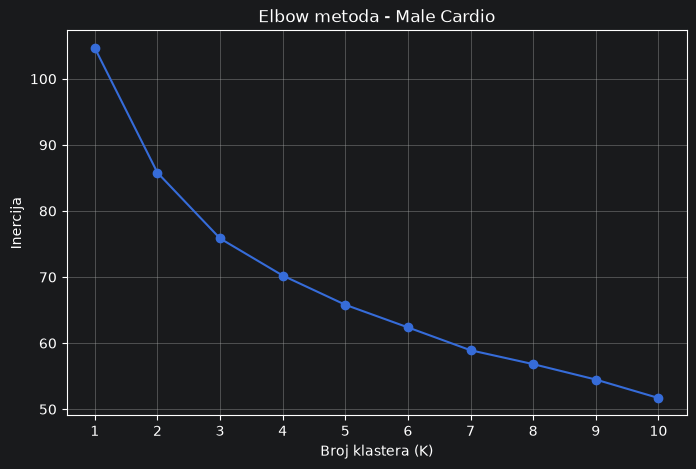

Rezultati Elbow metode:
K=1: Inercija=104.66
K=2: Inercija=85.80
K=3: Inercija=75.84
K=4: Inercija=70.23
K=5: Inercija=65.80
K=6: Inercija=62.38
K=7: Inercija=58.92
K=8: Inercija=56.82
K=9: Inercija=54.49
K=10: Inercija=51.70


In [22]:
from sklearn.cluster import KMeans

inertias = []
K = range(1, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_mc)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K, inertias, marker='o')
plt.xlabel('Broj klastera (K)')
plt.ylabel('Inercija')
plt.title('Elbow metoda - Male Cardio')
plt.xticks(K)
plt.grid(True)
plt.show()

print("Rezultati Elbow metode:")
for k, inertia in zip(K, inertias):
    print(f"K={k}: Inercija={inertia:.2f}")

In [23]:
#Na osnovu elbow metode ne mozemo jasno da odredimo koje je najbolje k,odnosno gde je lakat pa cemo da iskoristimo silhouette metodu

In [24]:
### 3.2. Silhouette metoda

K=2: Silhouette=0.2108
K=3: Silhouette=0.1542
K=4: Silhouette=0.1381
K=5: Silhouette=0.1366
K=6: Silhouette=0.1362
K=7: Silhouette=0.1454
K=8: Silhouette=0.1405
K=9: Silhouette=0.1191
K=10: Silhouette=0.1291


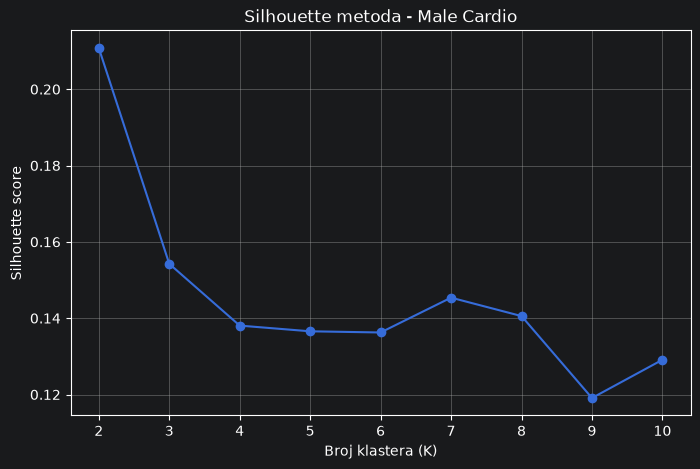

In [25]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_mc)
    score = silhouette_score(X_mc, labels)

    silhouette_scores.append(score)
    print(f"K={k}: Silhouette={score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.xlabel('Broj klastera (K)')
plt.ylabel('Silhouette score')
plt.title('Silhouette metoda - Male Cardio')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

In [26]:
#Jasno se vidi da je najbolje k=2 i nema potrebe razmotriti druge opcije zbog razlike u silhouette score

In [27]:
#3.3 Dendrogrami

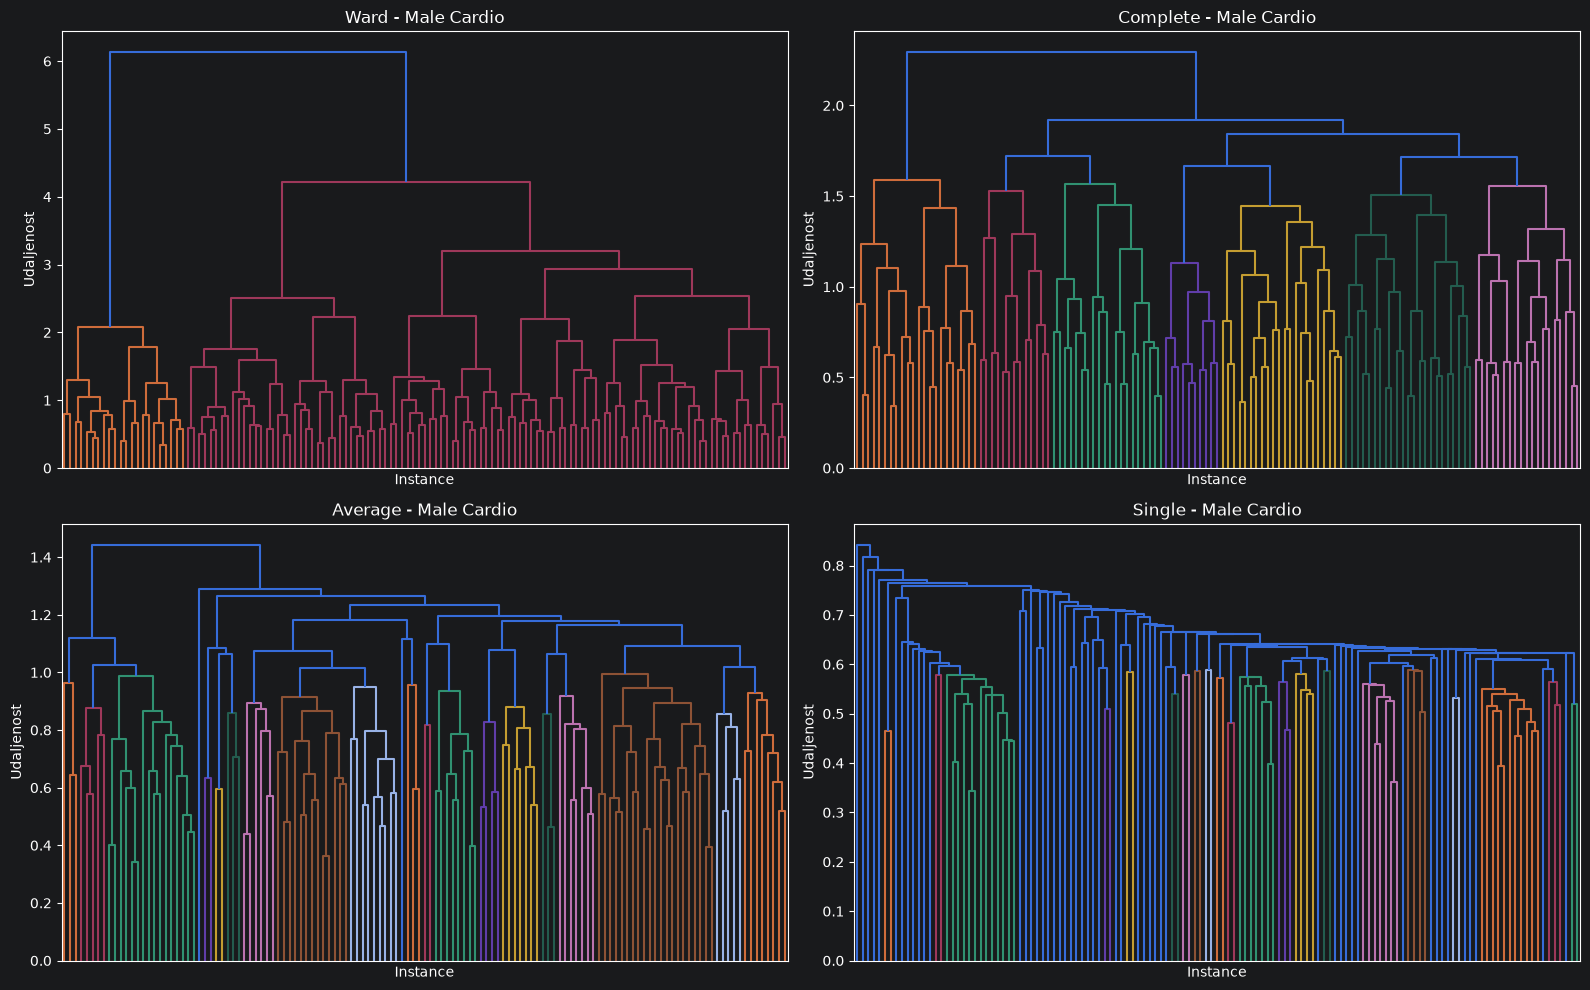

In [28]:
from scipy.cluster.hierarchy import linkage, dendrogram

methods = ['ward', 'complete', 'average', 'single']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, method in zip(axes.flatten(), methods):
    Z = linkage(X_mc, method=method)

    dendrogram(
        Z,
        ax=ax,
        no_labels=True
    )

    ax.set_title(f'{method.capitalize()} - Male Cardio')
    ax.set_xlabel('Instance')
    ax.set_ylabel('Udaljenost')

plt.tight_layout()
plt.show()

In [29]:
#Radi konzistenosti koristicemo ward dendrogram i na njemu jasno vidimo 2 dendrograma(narandzasti i rozi) pa cemo uzeti to kao broj za k,odnosno K=2

In [30]:
## 4. Klasterizacija i tumačenje klastera

### 4.1. KMeans klasterizacija i tumačenje klastera

In [31]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

df_mc['Cluster_KMeans'] = kmeans.fit_predict(X_mc)

print("Broj instanci po klasterima:")
print(df_mc['Cluster_KMeans'].value_counts().sort_index())

print("\nSilhouette score:")
print(silhouette_score(X_mc, df_mc['Cluster_KMeans']))

Broj instanci po klasterima:
Cluster_KMeans
0    105
1     24
Name: count, dtype: int64

Silhouette score:
0.21079518459361404


In [32]:
cluster_summary = df_mc.groupby('Cluster_KMeans')[
    features + ['Calories_Burned']
].mean().round(2)

print("Prosečne vrednosti atributa po klasterima:")
print(cluster_summary.to_string())

Prosečne vrednosti atributa po klasterima:
                  Age  Weight (kg)  Height (m)  Max_BPM  Avg_BPM  Resting_BPM  Session_Duration (hours)  Fat_Percentage  Water_Intake (liters)  Workout_Frequency (days/week)  Calories_Burned
Cluster_KMeans                                                                                                                                                                                
0               37.98        88.32        1.79   179.67   144.10        61.70                      1.13           25.18                   2.90                           2.96           860.63
1               39.75        83.92        1.80   175.75   141.67        64.12                      1.69           13.42                   3.51                           4.42          1250.04


In [33]:
#Klaster 0 ima 105 instanci opet nize trajanje treninga nizu ucestalost veci procenat masti i nizu potrosnju kalorija
#Klaster 1 ima 24 instance,duze trajanje treninga vecu ucestalost znatno nizi procenat masti i vecu potrosnju kalorija za oko 400

In [35]:
display(
    df_mc.groupby('Cluster_KMeans')[features + ['Calories_Burned']]
    .mean()
    .round(2)
)

,Age,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Calories_Burned
Cluster_KMeans,,,,,,,,,,,
0,37.98,88.32,1.79,179.67,144.10,61.70,1.13,25.18,2.90,2.96,860.63
1,39.75,83.92,1.80,175.75,141.67,64.12,1.69,13.42,3.51,4.42,1250.04


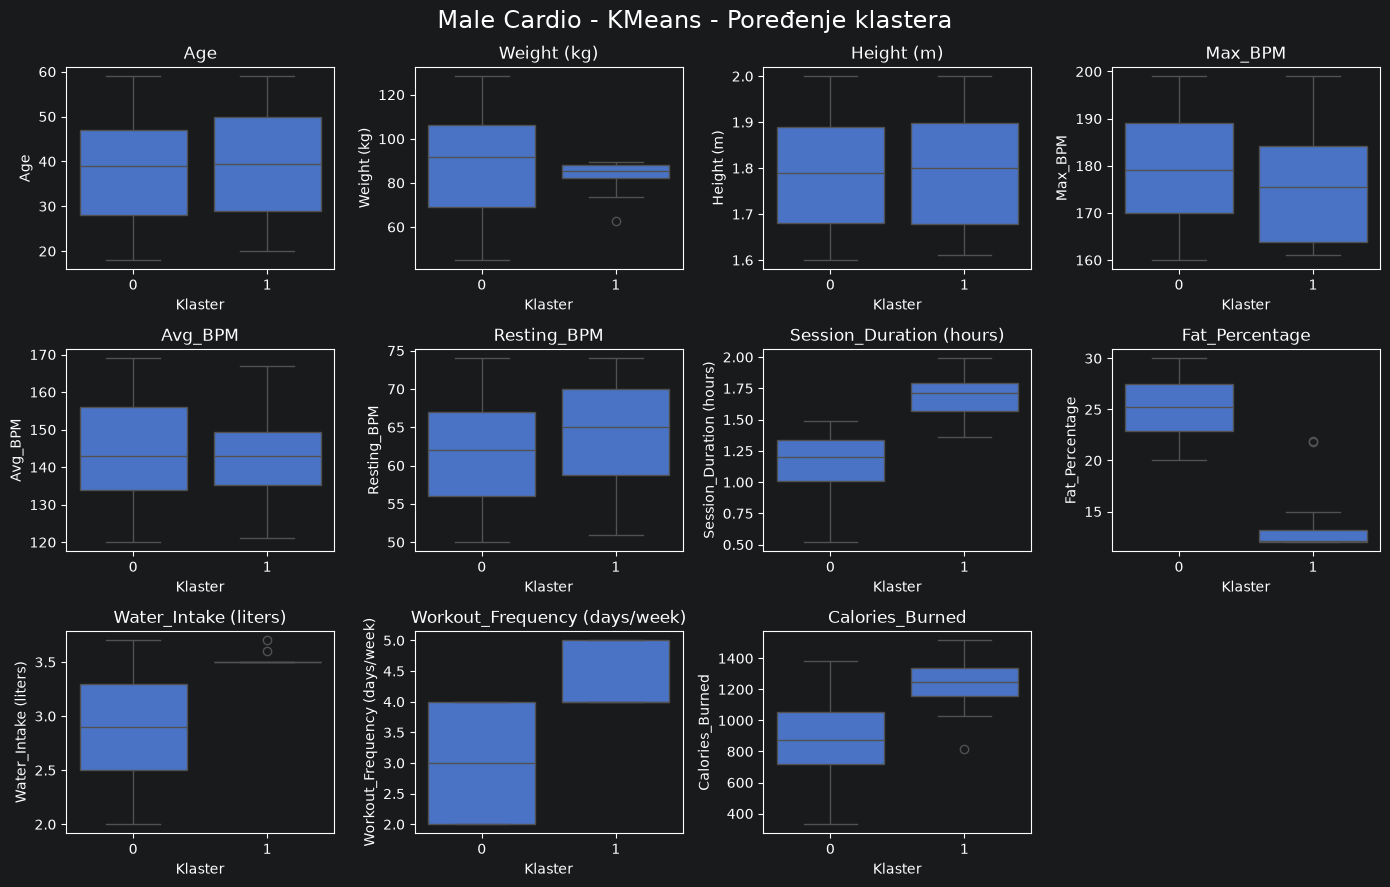

In [36]:
atributi = features + ['Calories_Burned']

fig, axes = plt.subplots(3, 4, figsize=(14, 9))

for ax, atribut in zip(axes.flatten(), atributi):
    sb.boxplot(
        data=df_mc,
        x='Cluster_KMeans',
        y=atribut,
        ax=ax
    )
    ax.set_title(atribut)
    ax.set_xlabel('Klaster')

# Uklanjanje praznog polja
for ax in axes.flatten()[len(atributi):]:
    ax.set_visible(False)

plt.suptitle(
    'Male Cardio - KMeans - Poređenje klastera',
    fontsize=17
)

plt.tight_layout()
plt.show()

In [ ]:
# Klaster 0 karakterišu kraći treninzi (1.13 h), manja učestalost
# treniranja (2.96 dana nedeljno), viši procenat telesne masti
# (25.18%) i niža prosečna potrošnja kalorija (860.63).
#
# Klaster 1 karakterišu duži treninzi (1.69 h), veća učestalost
# treniranja (4.42 dana nedeljno), niži procenat telesne masti
# (13.42%) i viša prosečna potrošnja kalorija (1250.04).
#
# Najizraženije razlike su u navikama treniranja, procentu telesne
# masti i potrošnji kalorija, dok je prosečna visina gotovo ista.

In [ ]:
### 4.2. Hijerarhijska klasterizacija i tumačenje klastera

In [ ]:
from sklearn.cluster import AgglomerativeClustering

methods = ['ward', 'complete', 'average', 'single']

for method in methods:
    model = AgglomerativeClustering(
        n_clusters=2,
        linkage=method
    )

    labels = model.fit_predict(X_mc)

    print(f"\n===== {method.upper()} =====")
    print("Broj instanci po klasterima:")
    print(pd.Series(labels).value_counts().sort_index())
    print(f"Silhouette score: {silhouette_score(X_mc, labels):.4f}")

In [ ]:
#Ward i Complete imaju najbolji Silhouette rezultat, nešto bolji od KMeans. Single daje izrazito neuravnoteženu podelu.
#Opet cemo radi konzistentnosti koristiti ward metodu

In [ ]:
ward = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

df_mc['Cluster_Ward'] = ward.fit_predict(X_mc)

ward_summary = df_mc.groupby('Cluster_Ward')[
    features + ['Calories_Burned']
].mean().round(2)

print("Prosečne vrednosti po Ward klasterima:")
print(ward_summary.to_string())

print("\nPoređenje KMeans i Ward klastera:")
print(pd.crosstab(
    df_mc['Cluster_KMeans'],
    df_mc['Cluster_Ward']
))

In [ ]:
#Zanimljivo je da ovde klaster 0 ima 2 instance vise od klastera 1 nego u Kmeans al rezultati su jako slicni svakako pa tumacili bi isto ko u kmeans